T = 10000
Nominal grid spacing h = 1/sqrt(T) = 0.01
Actual grid size d = 201, actual min step ≈ 0.01, max step ≈ 0.01

Discrete truncated Gaussian prior a1(i) ∝ exp(-x_i^2/(2 sigma0^2))
Chosen sigma0 = 0.280519
Mean ≈ 2.77556e-17,  StdDev ≈ 0.279864

Regret-related diameter term:
  D(a1) = max_i log(1/a1(i)) = 10.6066
  log(d) (uniform baseline)   = 5.3033
  Target c*log(d)             = 10.6066  (c=2.0)
  Worst-case regret inflation factor vs uniform init is sqrt(D/log d) ≈ 1.41421

Smallest r with P(|X-mean|>r) <= 0.10:  r ≈ 0.46  (actual tail ≈ 0.0970657)
Smallest r with P(|X-mean|>r) <= 0.05:  r ≈ 0.55  (actual tail ≈ 0.0496213)
Smallest r with P(|X-mean|>r) <= 0.01:  r ≈ 0.72  (actual tail ≈ 0.00993965)


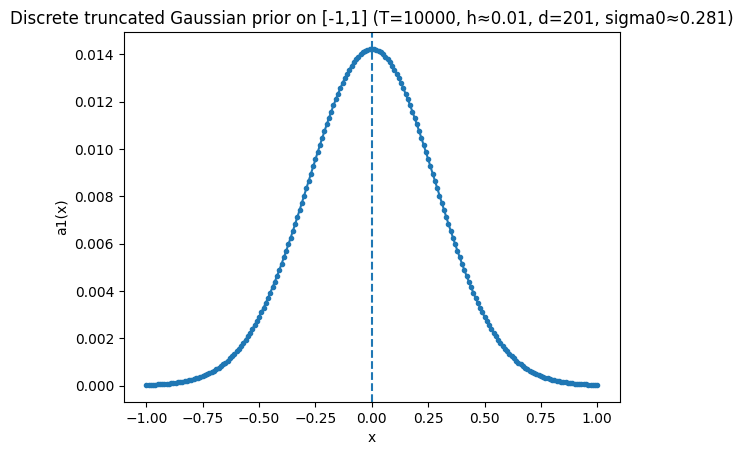

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

def make_grid(T: int):
    """
    Build a grid on [-1, 1] with nominal spacing h = 1/sqrt(T).
    If 2/h is not an integer, the last step may be smaller so we can include x=1 exactly.
    """
    h = 1.0 / math.sqrt(T)
    n = int(math.floor(2.0 / h))  # number of full steps of size h that fit in length 2
    x = -1.0 + h * np.arange(n + 1)
    if x[-1] < 1.0 - 1e-12:
        x = np.append(x, 1.0)  # include endpoint exactly
    d = len(x)
    return x, h, d

def discrete_truncated_gaussian(x: np.ndarray, sigma: float):
    """Unnormalized weights exp(-x^2/(2 sigma^2)) on grid, normalized to a pmf."""
    w = np.exp(-(x**2) / (2.0 * sigma**2))
    a = w / w.sum()
    return a

def diameter_term(a: np.ndarray):
    """D(a) := max_i log(1/a_i) = -log(min_i a_i)."""
    return -float(np.log(a.min()))

def find_sigma_for_regret_factor(T: int, c: float = 2.0, tol: float = 1e-12):
    """
    Choose the smallest sigma such that D(a1) <= c * log(d),
    where a1 is the discrete truncated Gaussian on the grid, and d = |grid|.

    Interpretation: compared to uniform initialization (which has D = log d),
    this makes the worst-case Hedge regret bound worse by at most a factor sqrt(c).

    c must be >= 1.0.
    """
    if c < 1.0:
        raise ValueError("c must be >= 1.0 (uniform is the minimax baseline).")

    x, h, d = make_grid(T)
    target = c * math.log(d)

    # Bracket sigma: small sigma => very peaked => D is huge; large sigma => near-uniform => D ~ log d.
    lo = 1e-6
    hi = 1.0
    while True:
        a_hi = discrete_truncated_gaussian(x, hi)
        if diameter_term(a_hi) <= target:
            break
        hi *= 2.0
        if hi > 100:
            raise RuntimeError("Could not bracket sigma (unexpected).")

    # Binary search for minimal sigma meeting the target.
    for _ in range(100):
        mid = 0.5 * (lo + hi)
        a_mid = discrete_truncated_gaussian(x, mid)
        if diameter_term(a_mid) <= target:
            hi = mid
        else:
            lo = mid
        if hi - lo <= tol * (1 + hi):
            break

    sigma = hi
    a = discrete_truncated_gaussian(x, sigma)
    D = diameter_term(a)
    return x, h, d, sigma, a, D, target

def distribution_summary(x: np.ndarray, a: np.ndarray):
    mean = float(np.sum(a * x))
    var = float(np.sum(a * (x - mean) ** 2))
    sd = math.sqrt(var)
    return mean, var, sd

def radius_for_tail_prob(x: np.ndarray, a: np.ndarray, delta: float):
    """Smallest r such that P(|X - E[X]| > r) <= delta."""
    mean = float(np.sum(a * x))
    dev = np.abs(x - mean)
    order = np.argsort(dev)
    cum = np.cumsum(a[order])
    idx = np.searchsorted(cum, 1.0 - delta, side="left")
    r = float(dev[order[min(idx, len(order) - 1)]])
    tail = float(1.0 - cum[min(idx, len(order) - 1)])
    return r, tail, mean

# -----------------------
# User inputs (edit these)
# -----------------------
def main(T, c):
    # T = 10_000               # horizon
    # T = 10_0               # horizon
    # c = 2.0                  # enforce D(a1) <= c * log(d); c=2 => regret inflation <= sqrt(2) vs uniform

    # Compute initialization
    x, h, d, sigma0, a1, D, target = find_sigma_for_regret_factor(T, c=c)
    mean, var, sd = distribution_summary(x, a1)

    # Report key numbers
    print(f"T = {T}")
    print(f"Nominal grid spacing h = 1/sqrt(T) = {1/math.sqrt(T):.6g}")
    print(f"Actual grid size d = {d}, actual min step ≈ {np.min(np.diff(x)):.6g}, max step ≈ {np.max(np.diff(x)):.6g}")
    print()
    print("Discrete truncated Gaussian prior a1(i) ∝ exp(-x_i^2/(2 sigma0^2))")
    print(f"Chosen sigma0 = {sigma0:.6g}")
    print(f"Mean ≈ {mean:.6g},  StdDev ≈ {sd:.6g}")
    print()
    print("Regret-related diameter term:")
    print(f"  D(a1) = max_i log(1/a1(i)) = {D:.6g}")
    print(f"  log(d) (uniform baseline)   = {math.log(d):.6g}")
    print(f"  Target c*log(d)             = {target:.6g}  (c={c})")
    print(f"  Worst-case regret inflation factor vs uniform init is sqrt(D/log d) ≈ {math.sqrt(D/math.log(d)):.6g}")
    print()

    # Some tail radii for intuition
    for delta in [0.10, 0.05, 0.01]:
        r, tail, _ = radius_for_tail_prob(x, a1, delta=delta)
        print(f"Smallest r with P(|X-mean|>r) <= {delta:.2f}:  r ≈ {r:.6g}  (actual tail ≈ {tail:.6g})")

    # Plot the pmf
    plt.figure()
    plt.plot(x, a1, marker=".", linestyle="-")
    plt.axvline(mean, linestyle="--")  # mean (near 0)
    plt.title(f"Discrete truncated Gaussian prior on [-1,1] (T={T}, h≈{h:.3g}, d={d}, sigma0≈{sigma0:.3g})")
    plt.xlabel("x")
    plt.ylabel("a1(x)")
    plt.show()

main(T=10000, c=2.0)

T = 200
Nominal grid spacing h = 1/sqrt(T) = 0.0707107
Actual grid size d = 30, actual min step ≈ 0.020101, max step ≈ 0.0707107

Discrete truncated Gaussian prior a1(i) ∝ exp(-x_i^2/(2 sigma0^2))
Chosen sigma0 = 0.340476
Mean ≈ 0.000854087,  StdDev ≈ 0.337544

Regret-related diameter term:
  D(a1) = max_i log(1/a1(i)) = 6.80239
  log(d) (uniform baseline)   = 3.4012
  Target c*log(d)             = 6.80239  (c=2.0)
  Worst-case regret inflation factor vs uniform init is sqrt(D/log d) ≈ 1.41421

Smallest r with P(|X-mean|>r) <= 0.10:  r ≈ 0.554781  (actual tail ≈ 0.0956274)
Smallest r with P(|X-mean|>r) <= 0.05:  r ≈ 0.647301  (actual tail ≈ 0.0468046)
Smallest r with P(|X-mean|>r) <= 0.01:  r ≈ 0.859433  (actual tail ≈ 0.00788971)


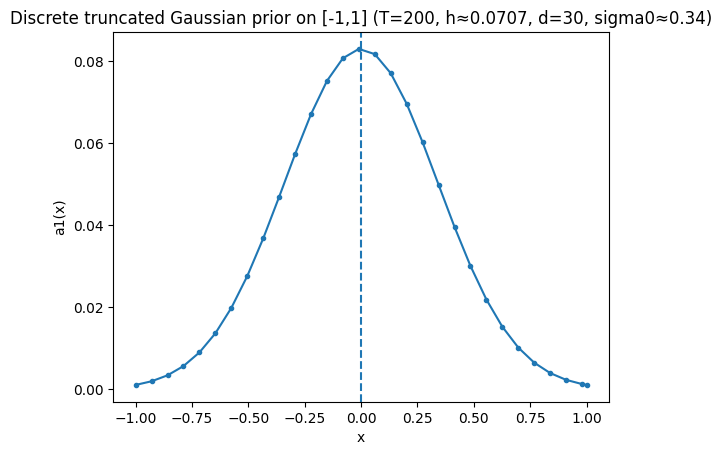

In [5]:
main(T=200, c=2.0)